In [66]:
# ==================================================
# PROJECT: Exploratory Data Analysis on Cars Dataset
# SECTION 1: Import Libraries
# ==================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [67]:
df = pd.read_csv('/content/Car details v3.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [68]:
# Display first 5 rows
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [69]:
# Number of rows and columns
print(df.shape)

(8128, 13)


In [70]:
# Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   object 
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   object 
 5   seller_type    8128 non-null   object 
 6   transmission   8128 non-null   object 
 7   owner          8128 non-null   object 
 8   mileage        7907 non-null   object 
 9   engine         7907 non-null   object 
 10  max_power      7913 non-null   object 
 11  torque         7906 non-null   object 
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), object(9)
memory usage: 825.6+ KB


In [71]:
# Numerical statistics
df.describe()

,year,selling_price,km_driven,seats
count,8128.000000,8.128000e+03,8.128000e+03,7907.000000
mean,2013.804011,6.382718e+05,6.981951e+04,5.416719
std,4.044249,8.062534e+05,5.655055e+04,0.959588
min,1983.000000,2.999900e+04,1.000000e+00,2.000000
25%,2011.000000,2.549990e+05,3.500000e+04,5.000000
50%,2015.000000,4.500000e+05,6.000000e+04,5.000000
75%,2017.000000,6.750000e+05,9.800000e+04,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,14.000000


In [72]:
#Check missing values:
df.isnull().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage,221
engine,221


In [73]:
#Check duplicate rows
df.duplicated().sum()

np.int64(1202)

In [74]:
#Check categorical columns
df.select_dtypes(include='object').nunique()

,0
name,2058
fuel,4
seller_type,3
transmission,2
owner,5
mileage,393
engine,121
max_power,322
torque,441


In [75]:
# Dataset size before cleaning
print("Before cleaning:", df.shape)

Before cleaning: (8128, 13)


In [76]:
# Remove duplicate rows
df = df.drop_duplicates()

print("Duplicates removed successfully")

Duplicates removed successfully


In [77]:
# Percentage of missing values in each column

(df.isnull().sum() / len(df) * 100).round(2)

,0
name,0.00
year,0.00
selling_price,0.00
km_driven,0.00
fuel,0.00
seller_type,0.00
transmission,0.00
owner,0.00
mileage,3.00
engine,3.00


In [78]:
# Check unique fuel types

df["fuel"].unique()

array(['Diesel', 'Petrol', 'LPG', 'CNG'], dtype=object)

In [79]:
# Check unique seller types

df["seller_type"].unique()

array(['Individual', 'Dealer', 'Trustmark Dealer'], dtype=object)

In [80]:
# Check unique transmission types

df["transmission"].unique()

array(['Manual', 'Automatic'], dtype=object)

In [81]:
# Check unique owner types

df["owner"].unique()

array(['First Owner', 'Second Owner', 'Third Owner',
       'Fourth & Above Owner', 'Test Drive Car'], dtype=object)

In [82]:
# Record dataset size after cleaning duplicates

df.shape

(6926, 13)

In [83]:
# Handling Missing Values

# Check missing values in each column
df.isnull().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage,208
engine,208


In [84]:
# Convert empty strings and whitespace-only values into NaN

df = df.replace(r'^\s*$', np.nan, regex=True)

In [85]:
# Check updated missing values

df.isnull().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage,208
engine,208


In [86]:
# Fill missing seats with the median

df["seats"] = df["seats"].fillna(df["seats"].median())

In [87]:
# Check missing values after filling seats

df.isnull().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage,208
engine,208


In [88]:
# Convert mileage to numeric values

df["mileage"] = df["mileage"].str.replace(" kmpl", "", regex=False)
df["mileage"] = df["mileage"].str.replace(" km/kg", "", regex=False)
df["mileage"] = pd.to_numeric(df["mileage"], errors="coerce")

In [89]:
# Convert engine to numeric values

df["engine"] = df["engine"].str.replace(" CC", "", regex=False)
df["engine"] = pd.to_numeric(df["engine"], errors="coerce")

In [90]:
# Convert maximum power to numeric values

df["max_power"] = df["max_power"].str.replace(" bhp", "", regex=False)
df["max_power"] = pd.to_numeric(df["max_power"], errors="coerce")

In [91]:
# Check data types after conversion

df.dtypes

,0
name,object
year,int64
selling_price,int64
km_driven,int64
fuel,object
seller_type,object
transmission,object
owner,object
mileage,float64
engine,float64


In [92]:
# Check missing values after conversion

df.isnull().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage,208
engine,208


In [93]:
# Fill missing values in numerical columns

df["mileage"] = df["mileage"].fillna(df["mileage"].median())
df["engine"] = df["engine"].fillna(df["engine"].median())
df["max_power"] = df["max_power"].fillna(df["max_power"].median())

In [94]:
# Check remaining missing values

df.isnull().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage,0
engine,0


In [95]:
# Check torque data type

df["torque"].dtype

dtype('O')

In [96]:
# Check different torque formats

df["torque"].dropna().unique()[:15]

array(['190Nm@ 2000rpm', '250Nm@ 1500-2500rpm', '12.7@ 2,700(kgm@ rpm)',
       '22.4 kgm at 1750-2750rpm', '11.5@ 4,500(kgm@ rpm)',
       '113.75nm@ 4000rpm', '7.8@ 4,500(kgm@ rpm)', '59Nm@ 2500rpm',
       '170Nm@ 1800-2400rpm', '160Nm@ 2000rpm', '248Nm@ 2250rpm',
       '78Nm@ 4500rpm', '84Nm@ 3500rpm', '115Nm@ 3500-3600rpm',
       '200Nm@ 1750rpm'], dtype=object)

In [97]:
# Clean the torque column

df["torque"] = df["torque"].str.extract(r"(\d+\.?\d*)")[0]
df["torque"] = pd.to_numeric(df["torque"], errors="coerce")

# Fill missing torque values with the median

df["torque"] = df["torque"].fillna(df["torque"].median())

In [98]:
# Check missing values

df.isnull().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage,0
engine,0


In [99]:
# Dataset size after cleaning

df.shape

(6926, 13)

In [100]:
# Identify numerical columns

df.select_dtypes(include="number").columns

Index(['year', 'selling_price', 'km_driven', 'mileage', 'engine', 'max_power',
       'torque', 'seats'],
      dtype='object')

In [101]:
# Identify categorical columns

df.select_dtypes(include="object").columns

Index(['name', 'fuel', 'seller_type', 'transmission', 'owner'], dtype='object')

In [102]:
# Summary of numerical columns

df.describe()

,year,selling_price,km_driven,mileage,engine,max_power,torque,seats
count,6926.000000,6.926000e+03,6.926000e+03,6926.000000,6926.000000,6926.000000,6926.000000,6926.000000
mean,2013.420300,5.172707e+05,7.399568e+04,19.464550,1425.398787,87.551527,160.406591,5.421600
std,4.078286,5.197670e+05,5.835810e+04,3.987878,487.026967,31.311523,90.272744,0.972171
min,1983.000000,2.999900e+04,1.000000e+00,0.000000,624.000000,0.000000,4.800000,2.000000
25%,2011.000000,2.500000e+05,4.000000e+04,16.950000,1197.000000,68.000000,99.000000,5.000000
50%,2014.000000,4.000000e+05,7.000000e+04,19.440000,1248.000000,81.830000,146.000000,5.000000
75%,2017.000000,6.335000e+05,1.000000e+05,22.320000,1498.000000,99.000000,200.000000,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,42.000000,3604.000000,400.000000,789.000000,14.000000


In [103]:
# Summary of categorical columns

df.describe(include="object")

,name,fuel,seller_type,transmission,owner
count,6926,6926,6926,6926,6926
unique,2058,4,3,2,5
top,Maruti Swift Dzire VDI,Diesel,Individual,Manual,First Owner
freq,118,3755,6218,6342,4242


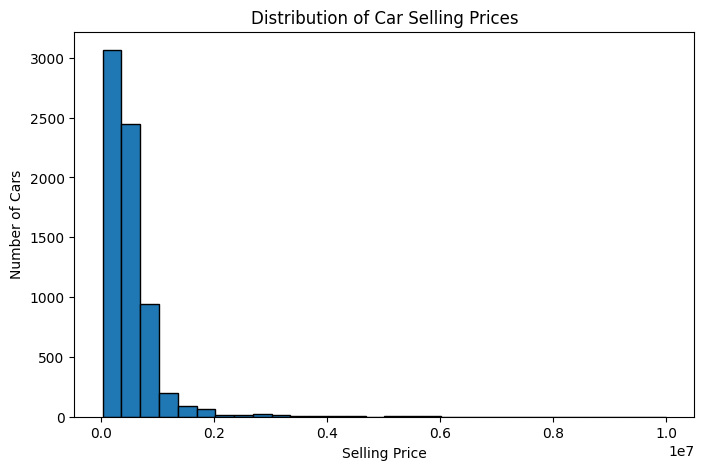

In [104]:
# Chart 1: Distribution of selling prices

plt.figure(figsize=(8, 5))
plt.hist(df["selling_price"], bins=30, edgecolor="black")

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")

plt.show()

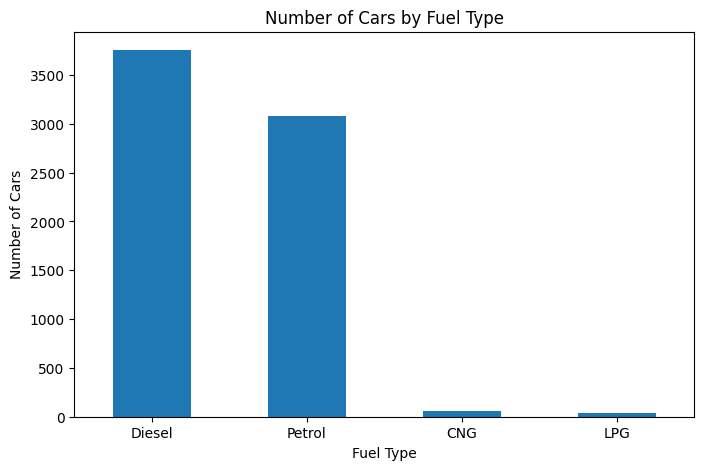

In [105]:
# Chart 2: Cars by fuel type

df["fuel"].value_counts().plot(kind="bar", figsize=(8, 5))

plt.title("Number of Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Cars")
plt.xticks(rotation=0)

plt.show()

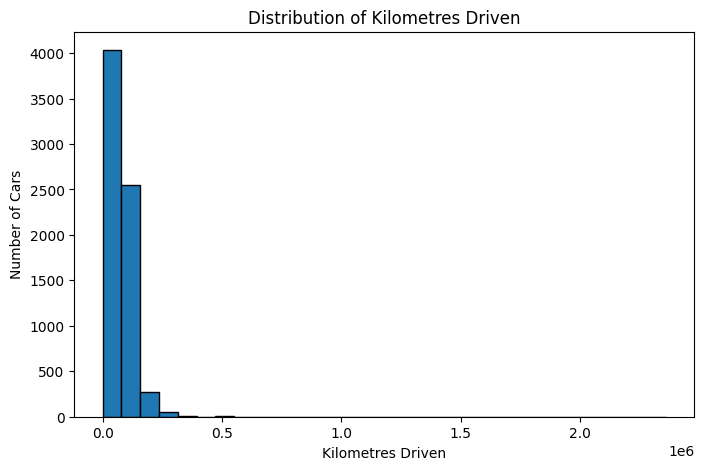

In [106]:
# Chart 3: Distribution of kilometres driven

plt.figure(figsize=(8, 5))
plt.hist(df["km_driven"], bins=30, edgecolor="black")

plt.title("Distribution of Kilometres Driven")
plt.xlabel("Kilometres Driven")
plt.ylabel("Number of Cars")

plt.show()

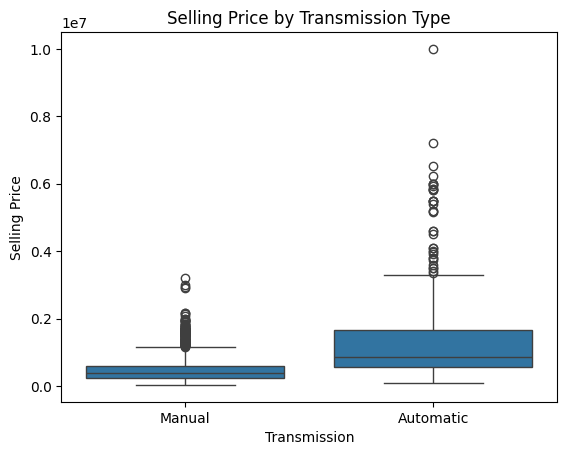

In [107]:
# Chart 4: Selling price by transmission type

sns.boxplot(data=df, x="transmission", y="selling_price")

plt.title("Selling Price by Transmission Type")
plt.xlabel("Transmission")
plt.ylabel("Selling Price")

plt.show()

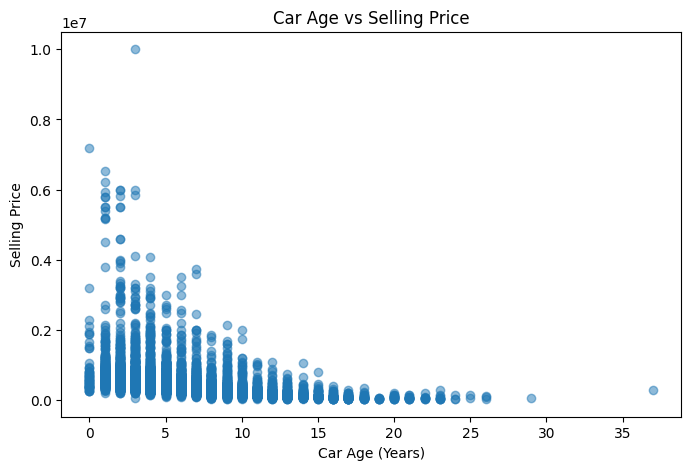

In [108]:
# Chart 5: Car age versus selling price

df["car_age"] = 2020 - df["year"]

plt.figure(figsize=(8, 5))
plt.scatter(df["car_age"], df["selling_price"], alpha=0.5)

plt.title("Car Age vs Selling Price")
plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price")

plt.show()

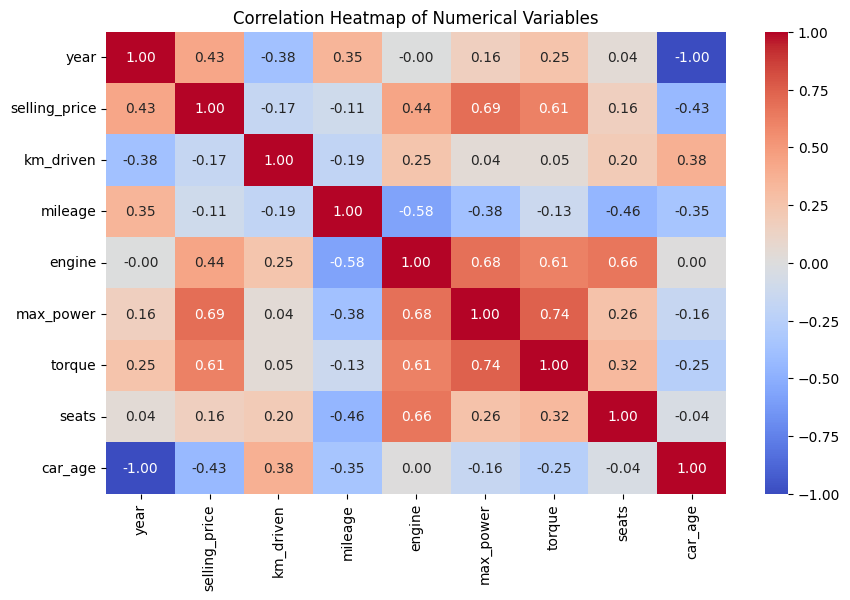

In [109]:
# Chart 6: Correlation between numerical variables

numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap of Numerical Variables")

plt.show()

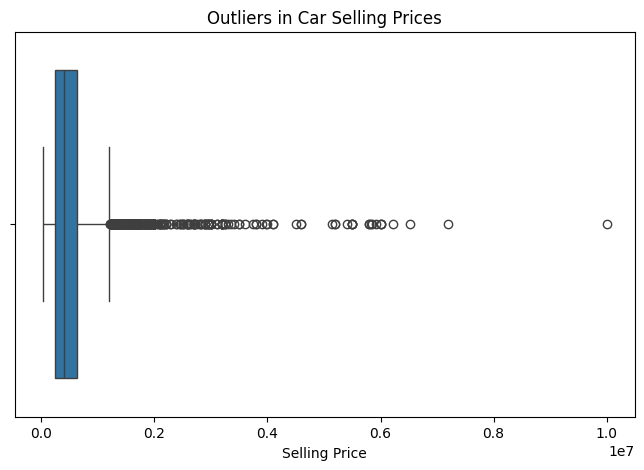

In [110]:
#  Outlier Analysis

plt.figure(figsize=(8, 5))
sns.boxplot(x=df["selling_price"])

plt.title("Outliers in Car Selling Prices")
plt.xlabel("Selling Price")

plt.show()

In [111]:
#  Correlation Analysis

df.select_dtypes(include="number").corr()

,year,selling_price,km_driven,mileage,engine,max_power,torque,seats,car_age
year,1.000000,0.433076,-0.377003,0.345699,-0.001064,0.158769,0.254858,0.042275,-1.000000
selling_price,0.433076,1.000000,-0.165620,-0.107372,0.444760,0.688838,0.614517,0.163942,-0.433076
km_driven,-0.377003,-0.165620,1.000000,-0.194716,0.246746,0.039490,0.046802,0.200999,0.377003
mileage,0.345699,-0.107372,-0.194716,1.000000,-0.577224,-0.377544,-0.132483,-0.458200,-0.345699
engine,-0.001064,0.444760,0.246746,-0.577224,1.000000,0.683027,0.611883,0.659422,0.001064
max_power,0.158769,0.688838,0.039490,-0.377544,0.683027,1.000000,0.742572,0.260458,-0.158769
torque,0.254858,0.614517,0.046802,-0.132483,0.611883,0.742572,1.000000,0.323040,-0.254858
seats,0.042275,0.163942,0.200999,-0.458200,0.659422,0.260458,0.323040,1.000000,-0.042275
car_age,-1.000000,-0.433076,0.377003,-0.345699,0.001064,-0.158769,-0.254858,-0.042275,1.000000


In [117]:
#  Key Findings

df["fuel"].value_counts()

,count
fuel,
Diesel,3755
Petrol,3077
CNG,56
LPG,38


In [118]:
# Average selling price by fuel type

df.groupby("fuel")["selling_price"].mean().sort_values(ascending=False)

,selling_price
fuel,
Diesel,639727.768842
Petrol,375688.966526
CNG,300499.946429
LPG,200421.052632


In [119]:
# Average selling price by transmission type

df.groupby("transmission")["selling_price"].mean()

,selling_price
transmission,
Automatic,1.309712e+06
Manual,4.442991e+05


In [120]:
# Average selling price by year

df.groupby("year")["selling_price"].mean().sort_index()

,selling_price
year,
1983,300000.000000
1991,55000.000000
1994,88000.000000
1995,107500.000000
1996,81666.666667
1997,90181.727273
1998,73100.000000
1999,71470.588235
2000,90047.850000


In [121]:
# Correlation with selling price

df.select_dtypes(include="number").corr()["selling_price"].sort_values(ascending=False)

,selling_price
selling_price,1.000000
max_power,0.688838
torque,0.614517
engine,0.444760
year,0.433076
seats,0.163942
mileage,-0.107372
km_driven,-0.165620
car_age,-0.433076


In [123]:
# Dataset Size Before and After Cleaning

dataset_size_before = (8128, 13)
dataset_size_after = df.shape

dataset_size_before, dataset_size_after

((8128, 13), (6926, 14))

In [124]:
#  Final Data Quality Check

df.shape

(6926, 14)

In [125]:
df.isnull().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage,0
engine,0


In [126]:
#  final dataset

df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,car_age
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,190.0,5.0,6
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,250.0,5.0,6
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,12.7,5.0,14
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,22.4,5.0,10
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,11.5,5.0,13
